# SmartSales AI
## Real-World Retail Sales Prediction and Real-Time Big Data Analytics System (Phase 1: Working Implementation)

**What this notebook does (in simple words):**
1. Downloads a **real** retail dataset (UCI *Online Retail*, real transactions of a UK online shop, Dec 2010 – Dec 2011).
2. Cleans it, handles returns/cancellations, and calculates revenue.
3. Explores it with charts (EDA).
4. Predicts **daily revenue** with Linear Regression and Random Forest, evaluated with MAE, MSE and R².
5. Tests whether weekday and weekend revenue differ (t-test).
6. Uses **Apache Spark Structured Streaming** to replay cleaned historical invoices as if they were arriving live, and shows a live transaction count, total revenue and average transaction value.

### Honesty box: what is real and what is simulated
| Part | Status |
|---|---|
| Sales records (all rows used for EDA, models, t-test) | **Real** historical data from the UCI Machine Learning Repository |
| Streaming | **Simulated replay.** Real, cleaned historical invoices are written to a folder a few at a time so Spark treats them as new events. It is **not** connected to a live retailer, a till, or any live data feed. |
| Model results | Whatever the code prints when you run it. Nothing in this notebook is pre-written or hard-coded. |
| Fake / randomly generated sales records | **None are used anywhere in this notebook.** |

**How to run:** In Google Colab choose *Runtime > Run all* (or run cells top to bottom with Shift+Enter). The first run takes roughly 5-10 minutes, mostly for the dataset download, reading the Excel file, and starting Spark. No GPU is needed.

## Demo-day quick start (read this first)

**Recommended: run this in Google Colab on the presentation Mac.** You do not need to install Python, Java, Spark, or an IDE on that Mac.

1. Open this notebook from Google Drive using Google Colab and sign in to the Google account that has access.
2. Choose **Runtime → Change runtime type → Python 3**. A GPU is not required.
3. Choose **Runtime → Run all** and approve any Google Colab prompts.
4. Keep the browser tab open while the dataset downloads, the models run, and the streaming replay completes.
5. Scroll to the final streaming verification and confirm **Overall: PASS** and **Active streams: 0**.

**Timing:** the full run can take several minutes and depends on Colab availability and network speed. Do not promise a 10-minute cold start. For a short live presentation, run the notebook before the session and keep the completed outputs available.

**If something fails:** choose **Runtime → Restart session**, then **Runtime → Run all**. Run cells from top to bottom; do not start the Spark cells before the dataset and invoice-event cells have run.

**Important:** this notebook uses real historical UCI transactions. Only the streaming arrival is simulated by replaying those real invoices.


## 0. Setup and installation

We install **PySpark 3.5.3** and **openpyxl**. Spark also needs Java. The setup checks the Java version already present in the runtime and installs OpenJDK 17 only if Java is missing.

A pip dependency-resolver warning about a separately preinstalled Spark Connect package may appear in Colab. It is not automatically a failure: the important checks are that PySpark imports, the Spark session starts, and the streaming validation passes.

If Colab explicitly asks for a runtime restart after installation, restart once and run all cells from the top.


In [1]:
# ---- Install the extra packages needed by this notebook ----
import subprocess, sys, os, re

def sh(cmd):
    """Run a shell command, show its final lines, and return its exit code."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip().splitlines()
    if out:
        print("\n".join(out[-6:]))
    if r.returncode != 0:
        raise RuntimeError(f"Command failed (exit {r.returncode}): {cmd}")
    return r.returncode

# Pin PySpark so the streaming code uses a consistent version.
sh(f"{sys.executable} -m pip install -q pyspark==3.5.3 openpyxl")

# Spark needs Java. Keep an existing Java installation (the verified Colab run
# used Java 21); install Java 17 only when Java is completely absent.
def java_major_version():
    try:
        out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        m = re.search(r'version "(\d+)', out)
        return int(m.group(1)) if m else None
    except FileNotFoundError:
        return None

jv = java_major_version()
print("Java major version found:", jv)
if jv is None:
    print("Java not found - installing OpenJDK 17...")
    sh("apt-get update -qq && apt-get install -y -qq openjdk-17-jdk-headless")
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    jv = java_major_version()
    print("Java major version now:", jv)

if jv is None:
    raise RuntimeError("Java is still unavailable. Restart the Colab runtime and run all cells again.")

import pyspark
print("PySpark version:", pyspark.__version__)
print("Setup checks passed. Spark session will be tested in the streaming section.")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.3 which is incompatible.
Java major version found: 21
PySpark version: 3.5.3
Setup checks passed. Spark session will be tested in the streaming section.


In [2]:
# ---- Imports and global settings ----
import os, time, shutil, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Folder where we keep downloaded and temporary files.
# In Google Colab this is /content. If you run the notebook elsewhere, it uses a local folder.
BASE_DIR = "/content" if os.path.isdir("/content") else os.path.abspath("smartsales_work")
os.makedirs(BASE_DIR, exist_ok=True)
print("Working folder:", BASE_DIR)

Working folder: /content


## 1. Download the real UCI Online Retail dataset
The dataset is published by the UCI Machine Learning Repository (dataset id 352). It holds about **541,909 line items** from a UK-based online gift shop, from **1 Dec 2010 to 9 Dec 2011**.

The cell tries three ways, in this order, so one failure does not stop you:
1. Direct download of the official zip file from UCI (preferred).
2. The `ucimlrepo` helper package (also fetches the same UCI dataset).
3. A manual upload of `Online Retail.xlsx` that you download yourself from the UCI page.

In [3]:
DATA_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
ZIP_PATH = os.path.join(BASE_DIR, "online_retail.zip")
XLSX_PATH = os.path.join(BASE_DIR, "Online Retail.xlsx")

def download_from_uci_zip():
    """Option 1: download the official zip and unzip the Excel file."""
    import requests
    print("Downloading from UCI:", DATA_URL)
    r = requests.get(DATA_URL, stream=True, timeout=180, headers={"User-Agent": "Mozilla/5.0"})
    r.raise_for_status()
    with open(ZIP_PATH, "wb") as f:
        for chunk in r.iter_content(chunk_size=1 << 20):
            f.write(chunk)
    with zipfile.ZipFile(ZIP_PATH) as z:
        xlsx_names = [n for n in z.namelist() if n.lower().endswith(".xlsx")]
        print("Files inside zip:", z.namelist())
        z.extract(xlsx_names[0], BASE_DIR)
        extracted = os.path.join(BASE_DIR, xlsx_names[0])
    if extracted != XLSX_PATH:
        shutil.move(extracted, XLSX_PATH)

def load_raw_data():
    """Returns (dataframe, description_of_source)."""
    # Reuse the file if it was already downloaded earlier in this session.
    if os.path.exists(XLSX_PATH):
        print("Found existing file:", XLSX_PATH)
    else:
        try:
            download_from_uci_zip()
        except Exception as e:
            print("Option 1 (direct zip download) failed:", repr(e))

    if os.path.exists(XLSX_PATH):
        print("Reading the Excel file (this can take 1-3 minutes for ~540k rows)...")
        df = pd.read_excel(XLSX_PATH, dtype={"InvoiceNo": str, "StockCode": str}, engine="openpyxl")
        return df, "UCI zip download (Online Retail.xlsx)"

    # Option 2: ucimlrepo package
    try:
        print("Trying Option 2: ucimlrepo package...")
        sh(f"{sys.executable} -m pip install -q ucimlrepo")
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=352)
        df = ds.data.original.copy()
        df["InvoiceNo"] = df["InvoiceNo"].astype(str)
        df["StockCode"] = df["StockCode"].astype(str)
        return df, "ucimlrepo (UCI dataset id 352)"
    except Exception as e:
        print("Option 2 failed:", repr(e))

    # Option 3: manual upload (Colab only)
    try:
        from google.colab import files
        print("Option 3: please upload 'Online Retail.xlsx' (download it from "
              "https://archive.ics.uci.edu/dataset/352/online+retail).")
        uploaded = files.upload()
        name = [n for n in uploaded if n.lower().endswith(".xlsx")][0]
        df = pd.read_excel(name, dtype={"InvoiceNo": str, "StockCode": str}, engine="openpyxl")
        return df, "manual upload"
    except Exception as e:
        raise RuntimeError("Could not obtain the dataset by any method. Download it manually from "
                           "https://archive.ics.uci.edu/dataset/352/online+retail and place "
                           f"'Online Retail.xlsx' in {BASE_DIR}") from e

raw_df, DATA_SOURCE = load_raw_data()
print("\nData source used:", DATA_SOURCE)
print("Rows loaded:", f"{len(raw_df):,}")
if len(raw_df) != 541909:
    print("NOTE: the official dataset has 541,909 rows. You loaded a different number - please check the source above.")
else:
    print("Row count matches the official 541,909 rows.")

Files inside zip: ['Online Retail.xlsx']
Reading the Excel file (this can take 1-3 minutes for ~540k rows)...

Data source used: UCI zip download (Online Retail.xlsx)
Rows loaded: 541,909
Row count matches the official 541,909 rows.


## 2. Load and inspect the data
Before changing anything we look at the raw data: the columns, data types, missing values and basic statistics.

**Column meanings**
- `InvoiceNo` – invoice (one customer purchase). An invoice starting with **C** is a **cancellation / return**.
- `StockCode` – product code
- `Description` – product name
- `Quantity` – number of units on that line (negative for returns)
- `InvoiceDate` – date and time of the invoice
- `UnitPrice` – price per unit in pounds sterling
- `CustomerID` – customer number (many are missing: guest checkouts)
- `Country` – customer country

Each **row is one product line**, and one invoice can have many rows.

In [4]:
print("Shape (rows, columns):", raw_df.shape)
display(raw_df.head())
print("\nData types:")
print(raw_df.dtypes)

Shape (rows, columns): (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom



Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [5]:
# Missing values per column
missing = raw_df.isna().sum().to_frame("missing_count")
missing["missing_percent"] = (missing["missing_count"] / len(raw_df) * 100).round(2)
display(missing)

print("Date range:", raw_df["InvoiceDate"].min(), "->", raw_df["InvoiceDate"].max())
print("Unique invoices:", f"{raw_df['InvoiceNo'].nunique():,}")
print("Unique customers (known):", f"{raw_df['CustomerID'].nunique():,}")
print("Unique countries:", raw_df["Country"].nunique())
print("Invoice numbers starting with 'C' (cancellations):", f"{raw_df['InvoiceNo'].astype(str).str.startswith('C').sum():,} rows")
print("Rows with Quantity <= 0:", f"{(raw_df['Quantity'] <= 0).sum():,}")
print("Rows with UnitPrice <= 0:", f"{(raw_df['UnitPrice'] <= 0).sum():,}")
print("Exact duplicate rows:", f"{raw_df.duplicated().sum():,}")
display(raw_df[["Quantity", "UnitPrice"]].describe())

,missing_count,missing_percent
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Date range: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
Unique invoices: 25,900
Unique customers (known): 4,372
Unique countries: 38
Invoice numbers starting with 'C' (cancellations): 9,288 rows
Rows with Quantity <= 0: 10,624
Rows with UnitPrice <= 0: 2,517
Exact duplicate rows: 5,268


,Quantity,UnitPrice
count,"541,909.00","541,909.00"
mean,9.55,4.61
std,218.08,96.76
min,"-80,995.00","-11,062.06"
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,"80,995.00","38,970.00"


## 3 & 4. Clean the data and handle cancellations / returns

### The treatment, explained simply
Real data is messy. We do **not** silently delete things; every step below prints how many rows it removed.

| Step | Rule | Why |
|---|---|---|
| A | Drop rows with a missing date, quantity, price or country | We cannot use a row without these |
| B | **Split out cancellations**: invoices starting with `C` go into a separate *returns* table | A return is not a sale. We keep it separately so we can still measure it. |
| C | From the remaining (non-cancellation) rows, remove `Quantity <= 0` | These are stock adjustments (damaged/lost items), not sales |
| D | Remove `UnitPrice <= 0` | Free items or accounting adjustments (e.g. bad-debt entries), not sales |
| E | Remove non-product codes (postage, bank charges, manual entries, Amazon fees, etc.) | They are service fees or accounting entries, not product demand |
| F | Remove exact duplicate rows | Likely accidental double-entries (this is a judgement call; you can switch it off below) |
| G | Remove extreme quantity lines (>= 10,000 units) and their matching cancellations | The raw data contains giant one-off orders that were reversed straight away; they would distort daily totals |

**Missing `CustomerID` is kept.** About a quarter of rows have no customer ID (guest orders). They are real sales and removing them would throw away a large share of revenue. Our analysis does not need the customer ID.

**Why returns are not subtracted from the daily sales target:** a return is usually processed on a *different day* from the original sale and the data does not link the two reliably. So we predict **gross sales revenue** (what customers bought) and report returns separately, so nothing is hidden.

In [6]:
# ---------- Settings you can change ----------
REMOVE_DUPLICATES = True      # set to False to keep exact duplicate rows
EXTREME_QTY = 10000           # lines with this many units or more are treated as extreme bulk entries

# Codes that are fees/adjustments rather than products
NON_PRODUCT_CODES = {"POST", "D", "DOT", "M", "BANK CHARGES", "AMAZONFEE", "S", "B", "CRUK", "PADS", "C2", "C3"}

df = raw_df.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["StockCode"] = df["StockCode"].astype(str).str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

cleaning_log = []   # we record (step, rows_removed) here
def log_step(name, before, after):
    cleaning_log.append({"step": name, "rows_before": before, "rows_after": after, "rows_removed": before - after})

# ---- A. Missing essential values ----
before = len(df)
df = df.dropna(subset=["InvoiceDate", "Quantity", "UnitPrice", "Country", "InvoiceNo", "StockCode"])
log_step("A. Drop rows missing date/quantity/price/country/invoice/stock code", before, len(df))

# ---- B. Split cancellations (invoice number starts with 'C') from normal invoices ----
is_cancel = df["InvoiceNo"].str.upper().str.startswith("C")
cancel_df = df[is_cancel].copy()          # returns table
sales_df = df[~is_cancel].copy()          # candidate sales
log_step("B. Move cancellation invoices (C...) to the returns table", len(df), len(sales_df))

# ---- C. Remove non-positive quantities from sales (stock adjustments) ----
before = len(sales_df)
sales_df = sales_df[sales_df["Quantity"] > 0]
log_step("C. Remove Quantity <= 0 from sales", before, len(sales_df))

# ---- D. Remove non-positive prices ----
before = len(sales_df)
sales_df = sales_df[sales_df["UnitPrice"] > 0]
log_step("D. Remove UnitPrice <= 0 from sales", before, len(sales_df))

# ---- E. Remove non-product stock codes ----
before = len(sales_df)
sales_df = sales_df[~sales_df["StockCode"].str.upper().isin(NON_PRODUCT_CODES)]
log_step("E. Remove non-product codes (postage, fees, manual...)", before, len(sales_df))

# ---- F. Exact duplicates ----
before = len(sales_df)
if REMOVE_DUPLICATES:
    sales_df = sales_df.drop_duplicates()
log_step("F. Remove exact duplicate rows" + ("" if REMOVE_DUPLICATES else " (SKIPPED)"), before, len(sales_df))

# ---- Clean the returns table the same way (only genuine product returns are kept) ----
cancel_df = cancel_df[(cancel_df["Quantity"] < 0) & (cancel_df["UnitPrice"] > 0)]
cancel_df = cancel_df[~cancel_df["StockCode"].str.upper().isin(NON_PRODUCT_CODES)]
if REMOVE_DUPLICATES:
    cancel_df = cancel_df.drop_duplicates()

# ---- G. Extreme quantities: first LOOK at them, then remove them ----
extreme = sales_df[sales_df["Quantity"] >= EXTREME_QTY]
print(f"Extreme sales lines (Quantity >= {EXTREME_QTY:,}): {len(extreme)}")
if len(extreme) > 0:
    display(extreme)
    # Was each one reversed by a cancellation with the same customer, product and quantity?
    reversals = extreme.merge(
        cancel_df.assign(abs_qty=-cancel_df["Quantity"])[["CustomerID", "StockCode", "abs_qty", "InvoiceNo", "InvoiceDate"]],
        left_on=["CustomerID", "StockCode", "Quantity"], right_on=["CustomerID", "StockCode", "abs_qty"],
        how="left", suffixes=("", "_cancel"))
    print("Matching cancellation found for each extreme line (blank = none found):")
    display(reversals[["InvoiceNo", "StockCode", "Quantity", "InvoiceDate", "InvoiceNo_cancel", "InvoiceDate_cancel"]])

before = len(sales_df)
sales_df = sales_df[sales_df["Quantity"] < EXTREME_QTY]
log_step(f"G. Remove extreme sales lines (>= {EXTREME_QTY:,} units)", before, len(sales_df))
cancel_df = cancel_df[cancel_df["Quantity"] > -EXTREME_QTY]   # keep returns consistent with sales

sales_df = sales_df.reset_index(drop=True)
cancel_df = cancel_df.reset_index(drop=True)

display(pd.DataFrame(cleaning_log))
print(f"\nRaw rows: {len(raw_df):,}")
print(f"Clean SALES rows kept: {len(sales_df):,}")
print(f"Clean RETURNS (cancellation) rows kept separately: {len(cancel_df):,}")

Extreme sales lines (Quantity >= 10,000): 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,"12,346.00",United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,"16,446.00",United Kingdom


Matching cancellation found for each extreme line (blank = none found):


,InvoiceNo,StockCode,Quantity,InvoiceDate,InvoiceNo_cancel,InvoiceDate_cancel
0,541431,23166,74215,2011-01-18 10:01:00,C541433,2011-01-18 10:17:00
1,581483,23843,80995,2011-12-09 09:15:00,C581484,2011-12-09 09:27:00


,step,rows_before,rows_after,rows_removed
0,A. Drop rows missing date/quantity/price/count...,541909,541909,0
1,B. Move cancellation invoices (C...) to the re...,541909,532621,9288
2,C. Remove Quantity <= 0 from sales,532621,531285,1336
3,D. Remove UnitPrice <= 0 from sales,531285,530104,1181
4,"E. Remove non-product codes (postage, fees, ma...",530104,527789,2315
5,F. Remove exact duplicate rows,527789,522568,5221
6,"G. Remove extreme sales lines (>= 10,000 units)",522568,522566,2



Raw rows: 541,909
Clean SALES rows kept: 522,566
Clean RETURNS (cancellation) rows kept separately: 8,666


## 5. Calculate revenue
Revenue for each line = **Quantity x UnitPrice** (in pounds sterling).
For returns the same formula gives a **negative** number (money handed back).

In [7]:
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]
cancel_df["ReturnValue"] = cancel_df["Quantity"] * cancel_df["UnitPrice"]   # negative numbers

gross_sales = sales_df["Revenue"].sum()
returns_value = cancel_df["ReturnValue"].sum()          # negative
net_revenue = gross_sales + returns_value

summary = pd.DataFrame({
    "value": [gross_sales, returns_value, net_revenue,
              abs(returns_value) / gross_sales * 100,
              sales_df["InvoiceNo"].nunique(), cancel_df["InvoiceNo"].nunique()]},
    index=["Gross sales revenue (GBP)", "Returns value (GBP, negative)", "Net revenue = sales + returns (GBP)",
           "Returns as % of gross sales", "Number of sales invoices", "Number of cancellation invoices"])
display(summary)

display(sales_df[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "Revenue", "Country"]].head())

,value
Gross sales revenue (GBP),"10,002,251.93"
"Returns value (GBP, negative)","-230,247.96"
Net revenue = sales + returns (GBP),"9,772,003.97"
Returns as % of gross sales,2.30
Number of sales invoices,"19,771.00"
Number of cancellation invoices,"3,420.00"


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,3.39,20.34,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34,United Kingdom


## 6. Exploratory Data Analysis (EDA)
Charts built from the **cleaned real sales data**. Each chart title says what to look for.

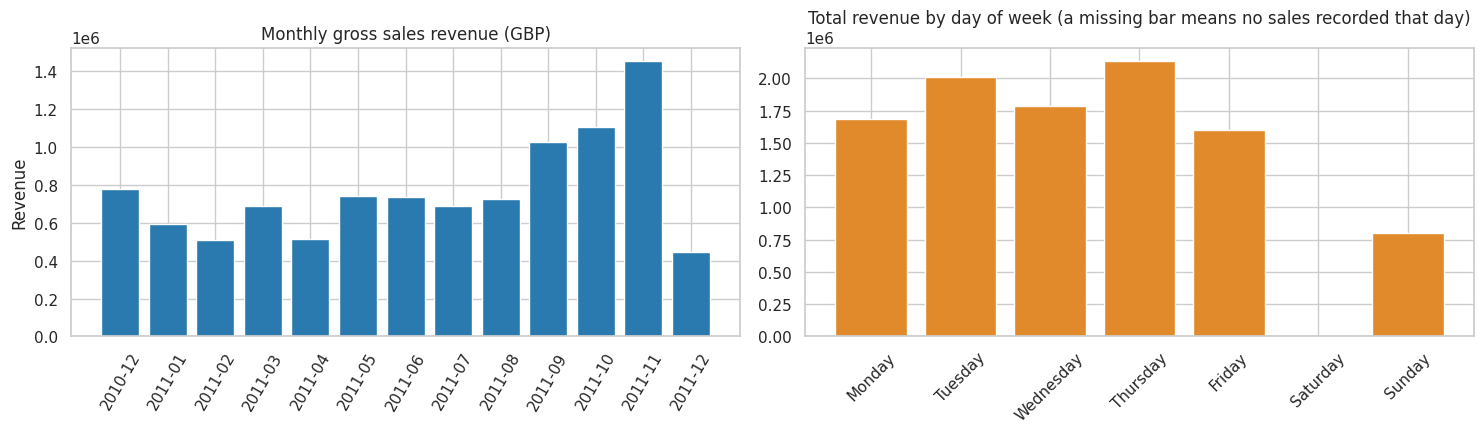

In [8]:
sales_df["Date"] = sales_df["InvoiceDate"].dt.normalize()
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M").astype(str)
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour
sales_df["DayName"] = sales_df["InvoiceDate"].dt.day_name()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# 1) Monthly revenue
monthly = sales_df.groupby("Month")["Revenue"].sum()
axes[0].bar(monthly.index, monthly.values, color="#2a7ab0")
axes[0].set_title("Monthly gross sales revenue (GBP)")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_ylabel("Revenue")

# 2) Revenue by day of week
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = sales_df.groupby("DayName")["Revenue"].sum().reindex(order)
axes[1].bar(by_day.index, by_day.fillna(0).values, color="#e08a2b")
axes[1].set_title("Total revenue by day of week (a missing bar means no sales recorded that day)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

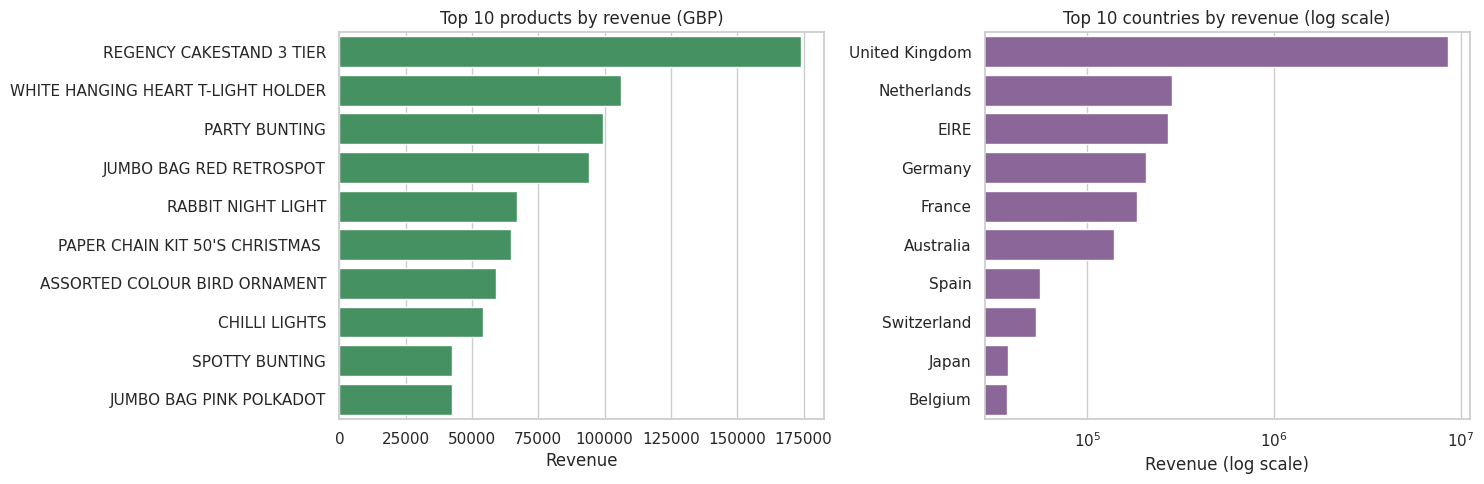

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 3) Top 10 products by revenue
top_products = (sales_df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10))
sns.barplot(x=top_products.values, y=top_products.index, ax=axes[0], color="#3a9d5d")
axes[0].set_title("Top 10 products by revenue (GBP)")
axes[0].set_xlabel("Revenue"); axes[0].set_ylabel("")

# 4) Top 10 countries by revenue (UK dominates, so we use a log scale to see the others)
top_countries = sales_df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1], color="#8e5ea2")
axes[1].set_xscale("log")
axes[1].set_title("Top 10 countries by revenue (log scale)")
axes[1].set_xlabel("Revenue (log scale)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

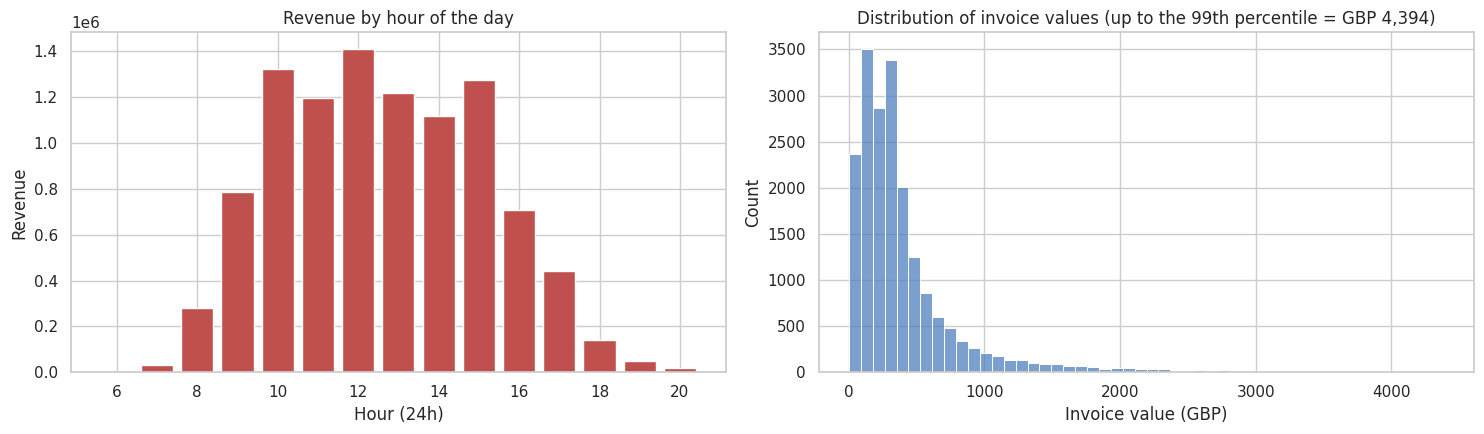

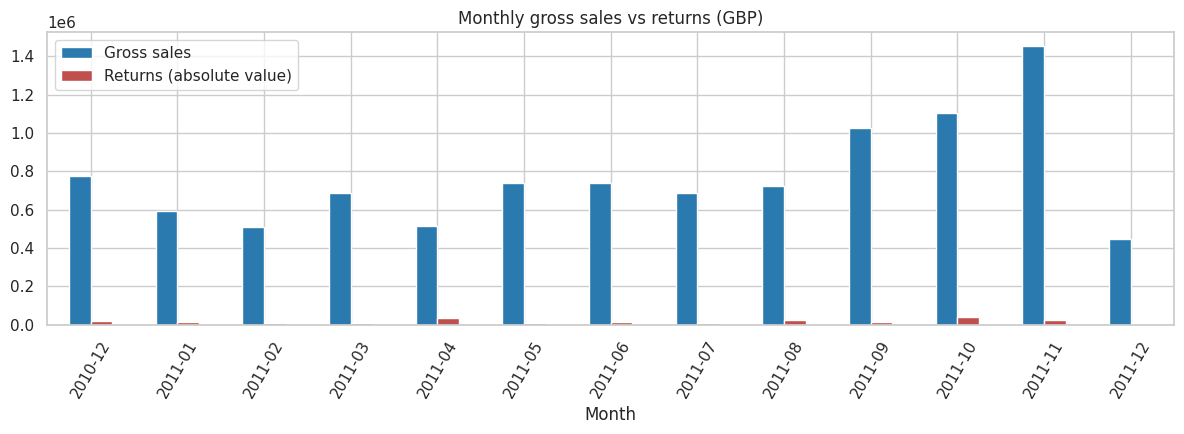

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# 5) Revenue by hour of day
by_hour = sales_df.groupby("Hour")["Revenue"].sum()
axes[0].bar(by_hour.index, by_hour.values, color="#c0504d")
axes[0].set_title("Revenue by hour of the day")
axes[0].set_xlabel("Hour (24h)"); axes[0].set_ylabel("Revenue")

# 6) Distribution of invoice values (clipped at the 99th percentile so the chart is readable)
invoice_values = sales_df.groupby("InvoiceNo")["Revenue"].sum()
cap = invoice_values.quantile(0.99)
sns.histplot(invoice_values[invoice_values <= cap], bins=50, ax=axes[1], color="#4f81bd")
axes[1].set_title(f"Distribution of invoice values (up to the 99th percentile = GBP {cap:,.0f})")
axes[1].set_xlabel("Invoice value (GBP)")
plt.tight_layout(); plt.show()

# 7) Returns by month (money handed back) next to sales, so you can see the scale of returns
cancel_df["Month"] = cancel_df["InvoiceDate"].dt.to_period("M").astype(str)
returns_monthly = (-cancel_df.groupby("Month")["ReturnValue"].sum()).reindex(monthly.index).fillna(0)
cmp_df = pd.DataFrame({"Gross sales": monthly, "Returns (absolute value)": returns_monthly})
cmp_df.plot(kind="bar", figsize=(12, 4.5), color=["#2a7ab0", "#c0504d"])
plt.title("Monthly gross sales vs returns (GBP)")
plt.xticks(rotation=60); plt.tight_layout(); plt.show()

## 7. Aggregate into daily sales
We add up all line items per calendar day to get one row per day: total revenue, number of invoices and units sold.

Two honest notes about this dataset, which the code checks and prints:
- **The shop recorded no sales on Saturdays**, so Saturday simply does not appear. The "weekend" in our data is therefore effectively **Sunday only**.
- **The data ends in the middle of 9 Dec 2011**, so the last day is incomplete. We drop that one partial day so it does not look like a sudden crash in sales.

Last timestamp in the data: 2011-12-09 12:50:00 -> that day is incomplete and will be excluded from daily modelling.
Number of trading days: 304
Days of the week that appear in the data:
DayName
Monday       47
Tuesday      52
Wednesday    53
Thursday     53
Friday       49
Saturday      0
Sunday       50
Name: count, dtype: int64


,Date,Revenue,Transactions,UnitsSold,DayName,DayOfWeek,IsWeekend
0,2010-12-01,"57,442.33",127,26808,Wednesday,2,False
1,2010-12-02,"47,596.42",141,31262,Thursday,3,False
2,2010-12-03,"44,788.90",68,16136,Friday,4,False
3,2010-12-05,"30,908.67",88,16163,Sunday,6,True
4,2010-12-06,"51,667.12",102,21592,Monday,0,False


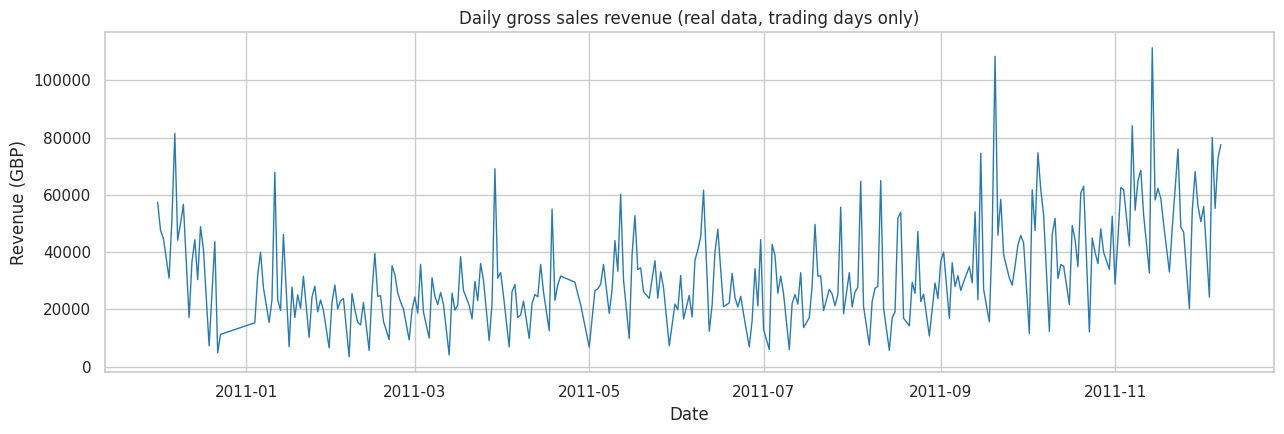

In [11]:
last_timestamp = df["InvoiceDate"].max()
last_day = last_timestamp.normalize()
print("Last timestamp in the data:", last_timestamp, "-> that day is incomplete and will be excluded from daily modelling.")

daily = (sales_df[sales_df["Date"] < last_day]
         .groupby("Date")
         .agg(Revenue=("Revenue", "sum"),
              Transactions=("InvoiceNo", "nunique"),
              UnitsSold=("Quantity", "sum"))
         .reset_index()
         .sort_values("Date")
         .reset_index(drop=True))

daily["DayName"] = daily["Date"].dt.day_name()
daily["DayOfWeek"] = daily["Date"].dt.dayofweek      # Monday=0 ... Sunday=6
daily["IsWeekend"] = daily["DayOfWeek"] >= 5

print("Number of trading days:", len(daily))
print("Days of the week that appear in the data:")
print(daily["DayName"].value_counts().reindex(order).fillna(0).astype(int))
display(daily.head())

plt.figure(figsize=(13, 4.5))
plt.plot(daily["Date"], daily["Revenue"], color="#2a7ab0", linewidth=1)
plt.title("Daily gross sales revenue (real data, trading days only)")
plt.ylabel("Revenue (GBP)"); plt.xlabel("Date")
plt.tight_layout(); plt.show()

## 9. Weekday vs weekend: independent samples t-test
**Question:** is the average daily revenue on weekdays different from the average on weekends?

- **H0 (null hypothesis):** mean daily revenue is the same for weekdays and weekends.
- **H1 (alternative):** the means are different (two-sided test).
- **Significance level:** 0.05. If the p-value is below 0.05 we reject H0.

We use **Welch's t-test** (`equal_var=False`), which is an independent samples t-test that does not assume both groups have the same variance. That is the safer choice when group sizes are very different (about five weekdays for every Sunday). We also print Levene's test so you can see whether the variances were similar.

**Caveat:** because Saturday has no data, the "weekend" group is Sunday only.

Weekday days: 254,  Weekend days: 50


,Weekday,Weekend
Number of days,254.00,50.00
Mean daily revenue (GBP),"36,119.35","15,966.23"
Std deviation (GBP),"17,012.40","9,964.33"


Welch t-statistic = 11.3999
p-value           = 1.472e-20
Levene test p-value (equal variances?) = 0.0056
Cohen's d (effect size) = 1.253
Decision: p < 0.05 -> reject H0. Weekday and weekend mean daily revenue are statistically different.


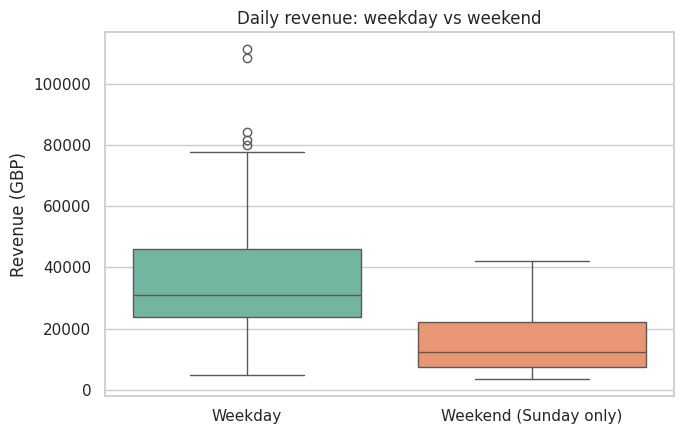

In [12]:
weekday_rev = daily.loc[~daily["IsWeekend"], "Revenue"]
weekend_rev = daily.loc[daily["IsWeekend"], "Revenue"]
print(f"Weekday days: {len(weekday_rev)},  Weekend days: {len(weekend_rev)}")

if len(weekend_rev) < 2 or len(weekday_rev) < 2:
    print("Not enough days in one of the groups to run the t-test.")
else:
    t_stat, p_val = stats.ttest_ind(weekday_rev, weekend_rev, equal_var=False)   # Welch's t-test
    lev_stat, lev_p = stats.levene(weekday_rev, weekend_rev)

    # Effect size (Cohen's d) tells us HOW BIG the difference is, not just whether it exists
    pooled_sd = np.sqrt(((len(weekday_rev) - 1) * weekday_rev.var(ddof=1) +
                         (len(weekend_rev) - 1) * weekend_rev.var(ddof=1)) /
                        (len(weekday_rev) + len(weekend_rev) - 2))
    cohens_d = (weekday_rev.mean() - weekend_rev.mean()) / pooled_sd

    result = pd.DataFrame({
        "Weekday": [len(weekday_rev), weekday_rev.mean(), weekday_rev.std()],
        "Weekend": [len(weekend_rev), weekend_rev.mean(), weekend_rev.std()]},
        index=["Number of days", "Mean daily revenue (GBP)", "Std deviation (GBP)"])
    display(result)
    print(f"Welch t-statistic = {t_stat:.4f}")
    print(f"p-value           = {p_val:.3e}")
    print(f"Levene test p-value (equal variances?) = {lev_p:.4f}")
    print(f"Cohen's d (effect size) = {cohens_d:.3f}")
    if p_val < 0.05:
        print("Decision: p < 0.05 -> reject H0. Weekday and weekend mean daily revenue are statistically different.")
    else:
        print("Decision: p >= 0.05 -> fail to reject H0. No statistically significant difference was found.")

    plt.figure(figsize=(7, 4.5))
    sns.boxplot(data=daily, x=np.where(daily["IsWeekend"], "Weekend (Sunday only)", "Weekday"), y="Revenue", palette="Set2")
    plt.title("Daily revenue: weekday vs weekend"); plt.xlabel(""); plt.ylabel("Revenue (GBP)")
    plt.tight_layout(); plt.show()

## 8, 10, 11, 12. Predicting daily revenue: features, chronological split, models, evaluation

### Features (inputs) the models use
- Day of week (one column per day, 1 = yes, 0 = no), day of month, month number
- `lag_1`: revenue of the **previous trading day**
- `lag_7`: revenue **7 trading days ago**
- `rolling_mean_7`: average revenue of the **previous 7 trading days**

All lag features only use the **past**. We deliberately do **not** use same-day information such as that day's invoice count, because that would leak the answer into the inputs.

### Chronological split (no future-data leakage)
We **do not shuffle**. The first 80% of days (oldest) are used for training and the last 20% (newest) for testing, like a real forecast where the future is unknown. Random shuffling would let the model "peek" at days after the ones it predicts.

### Baselines
We also report two very simple baselines (predict the training average; predict the previous trading day's revenue). A model is only useful if it beats these.

### Metrics
- **MAE** – average absolute error in pounds (easy to read)
- **MSE** – average squared error (punishes big misses)
- **R²** – 1 is perfect, 0 means no better than always guessing the average, negative means worse than that

In [13]:
feat = daily[["Date", "Revenue", "DayName"]].copy()
feat["day_of_month"] = feat["Date"].dt.day
feat["month"] = feat["Date"].dt.month
feat["lag_1"] = feat["Revenue"].shift(1)                              # previous trading day
feat["lag_7"] = feat["Revenue"].shift(7)                              # 7 trading days ago
feat["rolling_mean_7"] = feat["Revenue"].shift(1).rolling(7).mean()   # average of the previous 7 trading days

dow = pd.get_dummies(feat["DayName"], prefix="dow", dtype=int)        # one column per weekday that appears
feat = pd.concat([feat, dow], axis=1).dropna().reset_index(drop=True) # first 7 days have no lag values -> dropped

FEATURE_COLS = ["day_of_month", "month", "lag_1", "lag_7", "rolling_mean_7"] + list(dow.columns)

# ---- Chronological split: oldest 80% train, newest 20% test ----
split_index = int(len(feat) * 0.8)
train = feat.iloc[:split_index]
test = feat.iloc[split_index:]

X_train, y_train = train[FEATURE_COLS], train["Revenue"]
X_test, y_test = test[FEATURE_COLS], test["Revenue"]

print(f"Training days: {len(train)}  ({train['Date'].min().date()} -> {train['Date'].max().date()})")
print(f"Testing days : {len(test)}  ({test['Date'].min().date()} -> {test['Date'].max().date()})")
assert train["Date"].max() < test["Date"].min(), "Leakage check failed: train must come before test"
print("Leakage check passed: every training day is earlier than every test day.")
print("Features used:", FEATURE_COLS)
print("\nNote: the test period covers the most recent months of the dataset, which may contain busier "
      "seasonal weeks than the training period. Models can only learn patterns they saw in training.")

Training days: 237  (2010-12-09 -> 2011-09-29)
Testing days : 60  (2011-09-30 -> 2011-12-08)
Leakage check passed: every training day is earlier than every test day.
Features used: ['day_of_month', 'month', 'lag_1', 'lag_7', 'rolling_mean_7', 'dow_Friday', 'dow_Monday', 'dow_Sunday', 'dow_Thursday', 'dow_Tuesday', 'dow_Wednesday']

Note: the test period covers the most recent months of the dataset, which may contain busier seasonal weeks than the training period. Models can only learn patterns they saw in training.


In [14]:
def evaluate(name, y_true, y_pred):
    return {"Model": name,
            "MAE (GBP)": mean_absolute_error(y_true, y_pred),
            "MSE": mean_squared_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

# ---- Model 1: Linear Regression ----
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)
pred_lin = lin_model.predict(X_test)

# ---- Model 2: Random Forest Regressor ----
rf_model = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)

# ---- Simple baselines (for honest comparison) ----
pred_mean = np.full(len(y_test), y_train.mean())     # always predict the training average
pred_naive = X_test["lag_1"].values                  # predict "same as previous trading day"

results = pd.DataFrame([
    evaluate("Linear Regression", y_test, pred_lin),
    evaluate("Random Forest Regressor", y_test, pred_rf),
    evaluate("Baseline: training mean", y_test, pred_mean),
    evaluate("Baseline: previous trading day", y_test, pred_naive),
]).set_index("Model")
display(results)
print("All numbers above were computed on the held-out test period only (never seen during training).")

,MAE (GBP),MSE,R2
Model,,,
Linear Regression,"13,676.76","339,648,748.07",0.00
Random Forest Regressor,"12,722.65","305,610,641.20",0.10
Baseline: training mean,"24,566.11","841,618,244.92",-1.48
Baseline: previous trading day,"19,059.43","617,510,317.20",-0.82


All numbers above were computed on the held-out test period only (never seen during training).


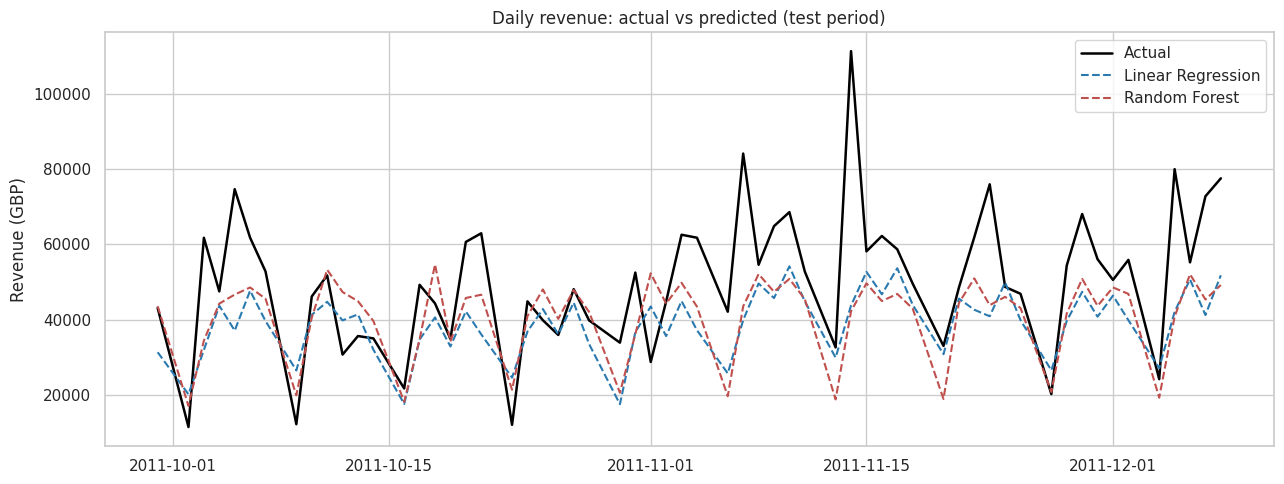

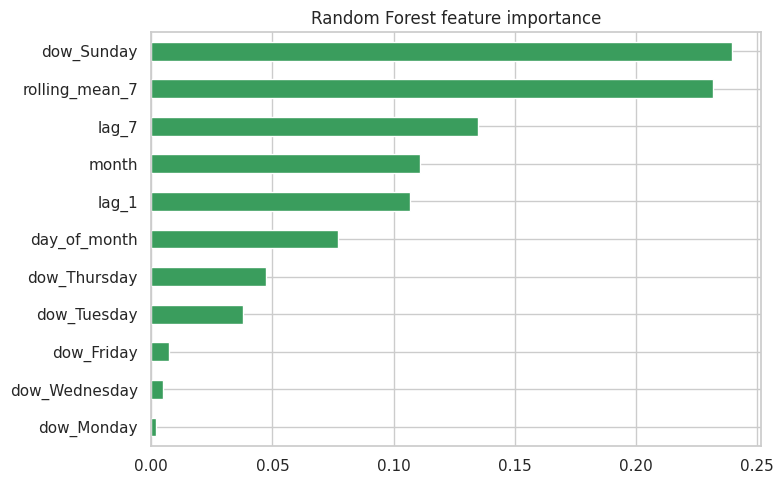

,coefficient
dow_Sunday,"-14,215.88"
dow_Friday,-500.01
dow_Monday,-417.33
day_of_month,-10.46
lag_7,-0.15
lag_1,0.04
rolling_mean_7,0.53
dow_Wednesday,277.83
month,551.20
dow_Tuesday,"6,815.24"


In [15]:
# ---- Actual vs predicted on the test period ----
plt.figure(figsize=(13, 5))
plt.plot(test["Date"], y_test.values, label="Actual", color="black", linewidth=1.8)
plt.plot(test["Date"], pred_lin, label="Linear Regression", color="#2a7ab0", linestyle="--")
plt.plot(test["Date"], pred_rf, label="Random Forest", color="#c0504d", linestyle="--")
plt.title("Daily revenue: actual vs predicted (test period)")
plt.ylabel("Revenue (GBP)"); plt.legend(); plt.tight_layout(); plt.show()

# ---- Which inputs did the Random Forest rely on most? ----
importances = pd.Series(rf_model.feature_importances_, index=FEATURE_COLS).sort_values()
importances.plot(kind="barh", figsize=(8, 5), color="#3a9d5d")
plt.title("Random Forest feature importance"); plt.tight_layout(); plt.show()

# ---- Linear Regression coefficients (the 'recipe' it learned) ----
coef = pd.Series(lin_model.coef_, index=FEATURE_COLS).sort_values()
display(coef.to_frame("coefficient"))

## 13, 14, 15. Apache PySpark Structured Streaming (simulated replay)

### What is happening here (simple explanation)
- **Structured Streaming** is Spark's engine for processing data that keeps arriving. You describe a calculation once, and Spark updates the answer every time new data shows up.
- We have no live retailer, so we **replay history**: real cleaned invoices (from the dataset) are saved in small CSV files that are dropped into a folder **one by one, a few seconds apart**. Spark watches the folder and treats each new file as new incoming events.
- **This is a simulation of a live feed.** The data is real, but its arrival timing is artificial. It is **not** connected to any live retailer.

### What counts as one "transaction"
One **invoice** = one customer transaction (basket). Each streamed event is one cleaned **sales invoice**, with its total value (sum of Quantity x UnitPrice over its product lines). Cancellations are not replayed as sales.

### What Spark calculates live
`transaction_count`, `total_revenue` and `average_transaction_value` over everything received so far.

In [16]:
# ---- Replay settings (you can change these) ----
NUM_BATCHES = 15              # how many small files are dropped into the stream folder
EVENTS_PER_BATCH = 100        # invoices per file  (15 x 100 = 1,500 invoices replayed)
SECONDS_BETWEEN_BATCHES = 3   # pause between files, to imitate arrival over time

# ---- Build one row per invoice from the cleaned REAL sales lines ----
invoice_events = (sales_df.groupby("InvoiceNo")
                  .agg(InvoiceDate=("InvoiceDate", "min"),
                       CustomerID=("CustomerID", "first"),
                       Country=("Country", "first"),
                       InvoiceRevenue=("Revenue", "sum"),
                       ItemCount=("Quantity", "sum"))
                  .reset_index()
                  .sort_values("InvoiceDate")
                  .reset_index(drop=True))

# Replay the most recent invoices in chronological order
replay_events = invoice_events.tail(NUM_BATCHES * EVENTS_PER_BATCH).copy().reset_index(drop=True)
replay_events["InvoiceRevenue"] = replay_events["InvoiceRevenue"].round(2)
replay_events["InvoiceDate"] = replay_events["InvoiceDate"].dt.strftime("%Y-%m-%d %H:%M:%S")
replay_events["CustomerID"] = replay_events["CustomerID"].apply(lambda x: "" if pd.isna(x) else str(int(x)))
replay_events["ItemCount"] = replay_events["ItemCount"].astype(int)

print(f"Total clean sales invoices available: {len(invoice_events):,}")
print(f"Invoices that will be replayed as stream events: {len(replay_events):,}")
print("Replay covers:", replay_events["InvoiceDate"].min(), "->", replay_events["InvoiceDate"].max())
display(replay_events.head())

# What the answer SHOULD be, calculated directly with Pandas (used later to verify Spark)
expected = {"transaction_count": len(replay_events),
            "total_revenue": round(float(replay_events["InvoiceRevenue"].sum()), 2),
            "average_transaction_value": round(float(replay_events["InvoiceRevenue"].mean()), 2)}
print("\nExpected final values (Pandas check):", expected)

Total clean sales invoices available: 19,771
Invoices that will be replayed as stream events: 1,500
Replay covers: 2011-11-23 12:20:00 -> 2011-12-09 12:50:00


,InvoiceNo,InvoiceDate,CustomerID,Country,InvoiceRevenue,ItemCount
0,578233,2011-11-23 12:20:00,14049,United Kingdom,"2,333.98",1658
1,578234,2011-11-23 12:22:00,13650,United Kingdom,298.24,130
2,578243,2011-11-23 12:33:00,13448,United Kingdom,"1,050.32",452
3,578244,2011-11-23 12:36:00,15727,United Kingdom,569.67,438
4,578246,2011-11-23 12:38:00,13991,United Kingdom,116.46,162



Expected final values (Pandas check): {'transaction_count': 1500, 'total_revenue': 784431.98, 'average_transaction_value': 522.95}


In [17]:
# ---- Start Spark (runs locally inside Colab, no cluster or paid service needed) ----
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, LongType

# If this cell is re-run, stop any old Spark session/streams first.
try:
    for q in SparkSession.builder.getOrCreate().streams.active:
        q.stop()
    SparkSession.builder.getOrCreate().stop()
except Exception:
    pass

spark = (SparkSession.builder
         .master("local[2]")                              # use 2 CPU cores on this machine
         .appName("SmartSalesAI")
         .config("spark.sql.shuffle.partitions", "2")     # small data -> few partitions = faster
         .config("spark.ui.enabled", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

Spark version: 3.5.3


In [18]:
# ---- Prepare folders: STREAM_DIR is the folder Spark watches for new files ----
STREAM_DIR = os.path.join(BASE_DIR, "stream_input")
STAGING_DIR = os.path.join(BASE_DIR, "stream_staging")
for d in (STREAM_DIR, STAGING_DIR):
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d, exist_ok=True)

# A stream needs a fixed schema (column names and types) in advance
event_schema = StructType([
    StructField("InvoiceNo", StringType(), True),
    StructField("InvoiceDate", StringType(), True),
    StructField("CustomerID", StringType(), True),
    StructField("Country", StringType(), True),
    StructField("InvoiceRevenue", DoubleType(), True),
    StructField("ItemCount", LongType(), True),
])

# Read the folder as a stream: each new CSV file becomes new events (one file per trigger)
stream_df = (spark.readStream
             .schema(event_schema)
             .option("header", "true")
             .option("maxFilesPerTrigger", 1)
             .csv(STREAM_DIR))

# Live calculations over everything received so far
live_metrics_df = stream_df.agg(
    F.count("*").alias("transaction_count"),
    F.round(F.sum("InvoiceRevenue"), 2).alias("total_revenue"),
    F.round(F.avg("InvoiceRevenue"), 2).alias("average_transaction_value"))

# Output: keep the latest answer in an in-memory table named 'live_metrics' that we can query
query = (live_metrics_df.writeStream
         .outputMode("complete")                          # re-send the full updated answer each time
         .format("memory")
         .queryName("live_metrics")
         .trigger(processingTime="1 second")
         .start())
print("Streaming query started. Is it active?", query.isActive)

Streaming query started. Is it active? True


In [19]:
# ---- Replay: drop one CSV file at a time into the watched folder and show the live numbers ----
def read_live_metrics():
    """Read the latest live numbers that Spark has computed (None if nothing yet)."""
    rows = spark.sql("SELECT * FROM live_metrics").collect()
    return rows[0].asDict() if rows else None

history = []          # (batch number, count, revenue, average) for the chart afterwards
final_metrics = None

print("SIMULATED REPLAY of real historical invoices - not a live retailer feed.\n")
try:
    for i in range(NUM_BATCHES):
        chunk = replay_events.iloc[i * EVENTS_PER_BATCH:(i + 1) * EVENTS_PER_BATCH]
        staged = os.path.join(STAGING_DIR, f"batch_{i:03d}.csv")
        chunk.to_csv(staged, index=False)
        # os.replace moves the finished file in one step, so Spark never sees a half-written file
        os.replace(staged, os.path.join(STREAM_DIR, f"batch_{i:03d}.csv"))

        time.sleep(SECONDS_BETWEEN_BATCHES)

        if query.exception() is not None:
            raise RuntimeError(f"Streaming query failed: {query.exception()}")
        m = read_live_metrics()
        if m and m["transaction_count"] is not None:
            history.append((i + 1, m["transaction_count"], m["total_revenue"], m["average_transaction_value"]))
            print(f"[file {i+1:02d}/{NUM_BATCHES}] transactions = {m['transaction_count']:>6,} | "
                  f"total revenue = GBP {m['total_revenue']:>12,.2f} | "
                  f"avg transaction value = GBP {m['average_transaction_value']:>8,.2f}")
        else:
            print(f"[file {i+1:02d}/{NUM_BATCHES}] waiting for Spark to process the first file...")

    # Give Spark time to finish processing the last files (up to 2 minutes)
    deadline = time.time() + 120
    while time.time() < deadline:
        m = read_live_metrics()
        if m and m["transaction_count"] == expected["transaction_count"]:
            break
        time.sleep(1)
    final_metrics = read_live_metrics()
    print("\nFinal live metrics:", final_metrics)

except KeyboardInterrupt:
    print("\nStopped manually by you (that is fine).")
except Exception as e:
    print("\nSomething went wrong during the stream:", repr(e))
finally:
    # CLEAN STOP: this always runs, even after an error, so no stream is left running in the background
    if query.isActive:
        query.stop()
    print("Streaming query stopped. Active streams left:", len(spark.streams.active))

SIMULATED REPLAY of real historical invoices - not a live retailer feed.

[file 01/15] waiting for Spark to process the first file...
[file 02/15] transactions =    100 | total revenue = GBP    59,773.41 | avg transaction value = GBP   597.73
[file 03/15] transactions =    300 | total revenue = GBP   148,600.03 | avg transaction value = GBP   495.33
[file 04/15] transactions =    400 | total revenue = GBP   183,935.25 | avg transaction value = GBP   459.84
[file 05/15] transactions =    500 | total revenue = GBP   243,858.61 | avg transaction value = GBP   487.72
[file 06/15] transactions =    600 | total revenue = GBP   291,386.34 | avg transaction value = GBP   485.64
[file 07/15] transactions =    700 | total revenue = GBP   343,931.93 | avg transaction value = GBP   491.33
[file 08/15] transactions =    800 | total revenue = GBP   386,533.46 | avg transaction value = GBP   483.17
[file 09/15] transactions =    900 | total revenue = GBP   429,223.84 | avg transaction value = GBP   4

transaction_count            Spark =          1,500   Pandas =          1,500   -> MATCH
total_revenue                Spark =     784,431.98   Pandas =     784,431.98   -> MATCH
average_transaction_value    Spark =         522.95   Pandas =         522.95   -> MATCH

Overall: PASS - streaming results match the direct calculation.


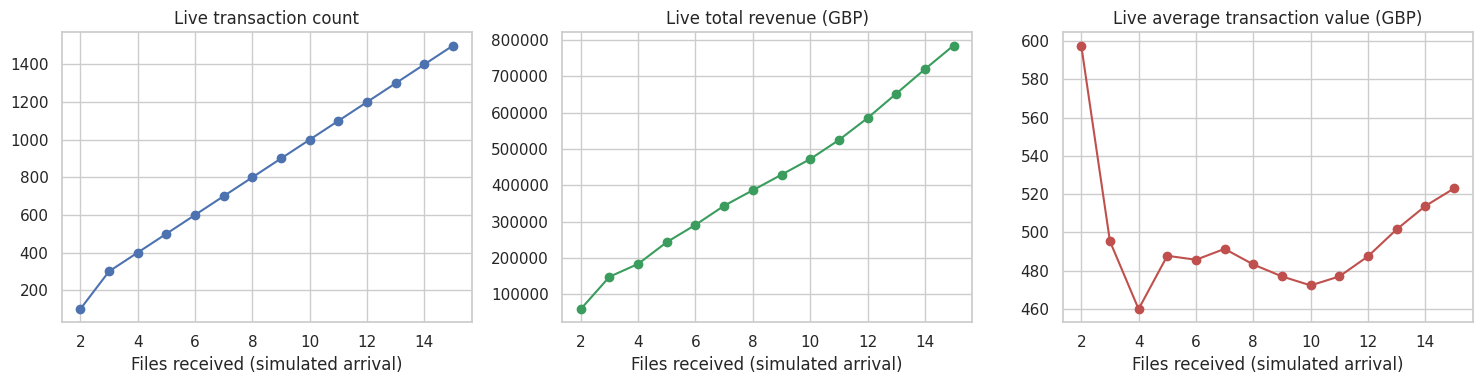

In [20]:
# ---- Verify that Spark's streaming answer matches the direct Pandas calculation ----
if final_metrics is None:
    print("No final metrics were captured (the stream may have been stopped early).")
else:
    checks = {
        "transaction_count": final_metrics["transaction_count"] == expected["transaction_count"],
        "total_revenue": abs(final_metrics["total_revenue"] - expected["total_revenue"]) < 0.05,
        "average_transaction_value": abs(final_metrics["average_transaction_value"] - expected["average_transaction_value"]) < 0.05,
    }
    for name, ok in checks.items():
        print(f"{name:28s} Spark = {final_metrics[name]:>14,}   Pandas = {expected[name]:>14,}   -> {'MATCH' if ok else 'MISMATCH'}")
    print("\nOverall:", "PASS - streaming results match the direct calculation." if all(checks.values())
          else "CHECK NEEDED - the stream had not processed every file (try increasing the wait) or something differs.")

# ---- Chart of how the live numbers grew as files arrived ----
if history:
    h = pd.DataFrame(history, columns=["files_received", "transactions", "total_revenue", "avg_value"])
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(h["files_received"], h["transactions"], marker="o"); axes[0].set_title("Live transaction count")
    axes[1].plot(h["files_received"], h["total_revenue"], marker="o", color="#3a9d5d"); axes[1].set_title("Live total revenue (GBP)")
    axes[2].plot(h["files_received"], h["avg_value"], marker="o", color="#c0504d"); axes[2].set_title("Live average transaction value (GBP)")
    for ax in axes: ax.set_xlabel("Files received (simulated arrival)")
    plt.tight_layout(); plt.show()

### Stopping and cleaning up
The streaming cell above stops its query automatically. Run the cell below to be extra sure everything is stopped, to shut Spark down, and to delete the temporary stream folders. You can skip it if you want to run the streaming section again.

In [21]:
# ---- Clean stop of everything Spark-related ----
try:
    for q in spark.streams.active:
        q.stop()
    print("Active streams:", len(spark.streams.active))
    spark.stop()
    print("Spark session stopped.")
except Exception as e:
    print("Nothing to stop or already stopped:", repr(e))

for d in (STREAM_DIR, STAGING_DIR):
    shutil.rmtree(d, ignore_errors=True)
print("Temporary stream folders removed.")

Active streams: 0
Spark session stopped.
Temporary stream folders removed.


## Short demonstration sequence (about 5–7 minutes, after the notebook has run)

1. **Dataset (30–45 sec):** show the UCI source and the 541,909 original records.
2. **Cleaning and EDA (45–60 sec):** explain cancellations/returns and show one or two charts.
3. **Statistics (45–60 sec):** explain H0, H1, Welch's t-test, p-value and the weekday-versus-Sunday limitation.
4. **Machine learning (60–90 sec):** show the chronological split, compare Linear Regression and Random Forest with the baselines, and explain that R² is modest.
5. **Big Data streaming (90–120 sec):** explain that each incoming file contains real historical invoices; show the changing count/revenue/average and the Spark-versus-Pandas MATCH results.
6. **Limitations (30 sec):** one retailer, one year, local Spark mode, and replay rather than a live retailer feed.

Do not claim that the model is highly accurate or that the stream is connected to a live business. Use the actual metrics printed by the run.


## Summary and limitations (read before presenting)
**What is real**
- All sales rows, the cleaning, the EDA, the daily aggregation, the t-test and both models use the **real UCI Online Retail dataset**. Every number is printed by the code when you run it.

**What is simulated**
- The streaming section **replays historical invoices** through a folder so Spark Structured Streaming can process them as arriving events. It is not connected to a live retailer.

**Known limitations**
- The dataset covers only about **one year** of one UK online shop, so models cannot learn full yearly seasonality, and the newest months (used for testing) may include seasonal peaks the models never saw in training.
- The test set is small (a few dozen trading days), so MAE/MSE/R² can change noticeably with small data or split changes.
- There are **no Saturday sales**, so the "weekend" t-test group is Sunday only; the last partial day (9 Dec 2011) was excluded from daily modelling.
- Lag features use *previous trading days*, not previous calendar days, because non-trading days are absent from the data.
- Exact-duplicate removal and the extreme-quantity rule are cleaning decisions (switchable at the top of the cleaning cell), not facts about the data.
- Spark runs in **local mode** on one machine: it demonstrates real Structured Streaming APIs, not cluster-scale throughput.